# **Market Basket Analysis**
---

- Task : Association Rules
- Objective : Menemukan Hubungan (association) Antara Item-Item Dalam Transaksi.

![](https://miro.medium.com/v2/resize:fit:1400/1*4yFCbNwp0gGdGR5KbquFHA.png)

# Import All Libraries

In [40]:
import pandas as pd
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy import stats
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from itertools import combinations
from collections import defaultdict

import warnings
warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [41]:
url = "https://raw.githubusercontent.com/agungibr/Bussiness-Analytics/refs/heads/main/dataset/france_dataset.csv"

df = pd.read_csv(url)

In [42]:
# Baca dataset
df.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536370,22728,ALARM CLOCK BAKELIKE PINK,24,12/1/2010 8:45,3.75,12583.0,France
1,536370,22727,ALARM CLOCK BAKELIKE RED,24,12/1/2010 8:45,3.75,12583.0,France
2,536370,22726,ALARM CLOCK BAKELIKE GREEN,12,12/1/2010 8:45,3.75,12583.0,France
3,536370,21724,PANDA AND BUNNIES STICKER SHEET,12,12/1/2010 8:45,0.85,12583.0,France
4,536370,21883,STARS GIFT TAPE,24,12/1/2010 8:45,0.65,12583.0,France


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8557 entries, 0 to 8556
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    8557 non-null   object 
 1   StockCode    8557 non-null   object 
 2   ProductName  8557 non-null   object 
 3   Quantity     8557 non-null   int64  
 4   InvoiceDate  8557 non-null   object 
 5   UnitPrice    8557 non-null   float64
 6   CustomerID   8491 non-null   float64
 7   Country      8557 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 534.9+ KB


In [44]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,0
ProductName,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,66
Country,0


# Data Cleaning

In [45]:
df_clean = df.copy()

In [46]:
# konversi tanggal
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], errors='coerce')
df_clean.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536370,22728,ALARM CLOCK BAKELIKE PINK,24,2010-12-01 08:45:00,3.75,12583.0,France
1,536370,22727,ALARM CLOCK BAKELIKE RED,24,2010-12-01 08:45:00,3.75,12583.0,France
2,536370,22726,ALARM CLOCK BAKELIKE GREEN,12,2010-12-01 08:45:00,3.75,12583.0,France
3,536370,21724,PANDA AND BUNNIES STICKER SHEET,12,2010-12-01 08:45:00,0.85,12583.0,France
4,536370,21883,STARS GIFT TAPE,24,2010-12-01 08:45:00,0.65,12583.0,France


In [47]:
# menghapus semua baris tanpa customer_id
df_clean.drop('CustomerID', axis=1, inplace=True)
df_clean.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,Country
0,536370,22728,ALARM CLOCK BAKELIKE PINK,24,2010-12-01 08:45:00,3.75,France
1,536370,22727,ALARM CLOCK BAKELIKE RED,24,2010-12-01 08:45:00,3.75,France
2,536370,22726,ALARM CLOCK BAKELIKE GREEN,12,2010-12-01 08:45:00,3.75,France
3,536370,21724,PANDA AND BUNNIES STICKER SHEET,12,2010-12-01 08:45:00,0.85,France
4,536370,21883,STARS GIFT TAPE,24,2010-12-01 08:45:00,0.65,France


In [48]:
# membuat semua product_name berhuruf kecil
df_clean['ProductName'] = df_clean['ProductName'].str.lower()
df_clean.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,Country
0,536370,22728,alarm clock bakelike pink,24,2010-12-01 08:45:00,3.75,France
1,536370,22727,alarm clock bakelike red,24,2010-12-01 08:45:00,3.75,France
2,536370,22726,alarm clock bakelike green,12,2010-12-01 08:45:00,3.75,France
3,536370,21724,panda and bunnies sticker sheet,12,2010-12-01 08:45:00,0.85,France
4,536370,21883,stars gift tape,24,2010-12-01 08:45:00,0.65,France


In [49]:
print("Unique values for ProductName:")
print(df['ProductName'].unique())

Unique values for ProductName:
['ALARM CLOCK BAKELIKE PINK' 'ALARM CLOCK BAKELIKE RED '
 'ALARM CLOCK BAKELIKE GREEN' ... 'SNACK TRAY I LOVE LONDON'
 'SET OF 6 RIBBONS PERFECTLY PRETTY  ' 'VICTORIAN SEWING BOX LARGE']


In [50]:
# menghapus baris dengan status cancelled, yaitu yang InvoiceNo-nya diawali 'C'
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

In [51]:
# mengubah nilai quantity yang negatif menjadi positif karena nilai negatif tersebut hanya menandakan order tersebut cancelled
df_clean['Quantity'] = df_clean['Quantity'].abs()

In [52]:
# menghapus baris dengan price bernilai negatif
df_clean = df_clean[df_clean['UnitPrice'] > 0]

In [53]:
# membuat nilai amount, yaitu perkalian antara quantity dan price
df_clean['Amount'] = df_clean['Quantity'] * df_clean['UnitPrice']

In [54]:
# Mencari product_name terbanyak per StockCode
most_freq_name = (
    df_clean.groupby(['StockCode', 'ProductName'], as_index=False)
            .agg(order_cnt=('InvoiceNo', 'nunique'))
            .sort_values(['StockCode', 'order_cnt'], ascending=[True, False])
)

In [55]:
# Ranking per StockCode
most_freq_name['rank'] = most_freq_name.groupby('StockCode')['order_cnt']\
                                       .rank(method='first', ascending=False)

In [56]:
# Ambil product_name paling sering untuk setiap StockCode
most_freq_name = most_freq_name[most_freq_name['rank'] == 1]\
                               .drop(columns=['order_cnt', 'rank'])

In [57]:
# Merge ke dataset asli
df_clean = df_clean.merge(
    most_freq_name.rename(columns={'ProductName': 'FixedName'}),
    how='left',
    on='StockCode'
)

In [58]:
# Ganti ProductName dengan FixedName
df_clean['ProductName'] = df_clean['FixedName']

In [59]:
# Hapus kolom temporary
df_clean.drop(columns=['FixedName'], inplace=True)
df_clean.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,Country,Amount
0,536370,22728,alarm clock bakelike pink,24,2010-12-01 08:45:00,3.75,France,90.0
1,536370,22727,alarm clock bakelike red,24,2010-12-01 08:45:00,3.75,France,90.0
2,536370,22726,alarm clock bakelike green,12,2010-12-01 08:45:00,3.75,France,45.0
3,536370,21724,panda and bunnies sticker sheet,12,2010-12-01 08:45:00,0.85,France,10.2
4,536370,21883,stars gift tape,24,2010-12-01 08:45:00,0.65,France,15.6


In [60]:
# mengganti product_name dari product_code yang memiliki beberapa product_name dengan salah satu product_name-nya yang paling sering muncul
most_freq_product_name = (
    df_clean.groupby(['StockCode','ProductName'], as_index=False)
    .agg(order_cnt=('InvoiceNo','nunique'))
    .sort_values(['StockCode','order_cnt'], ascending=[True, False])
)

most_freq_product_name['rank'] = (most_freq_product_name.groupby('StockCode')['order_cnt'].rank(method='first', ascending=False))

most_freq_product_name = most_freq_product_name[most_freq_product_name['rank'] == 1]
most_freq_product_name = most_freq_product_name.drop(columns=['order_cnt','rank'])

df_clean = df_clean.merge(most_freq_product_name.rename(columns={'ProductName':'MostFreqProductName'}), how='left', on='StockCode')

df_clean['ProductName'] = df_clean['MostFreqProductName']
df_clean = df_clean.drop(columns='MostFreqProductName')
df_clean.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,Country,Amount
0,536370,22728,alarm clock bakelike pink,24,2010-12-01 08:45:00,3.75,France,90.0
1,536370,22727,alarm clock bakelike red,24,2010-12-01 08:45:00,3.75,France,90.0
2,536370,22726,alarm clock bakelike green,12,2010-12-01 08:45:00,3.75,France,45.0
3,536370,21724,panda and bunnies sticker sheet,12,2010-12-01 08:45:00,0.85,France,10.2
4,536370,21883,stars gift tape,24,2010-12-01 08:45:00,0.65,France,15.6


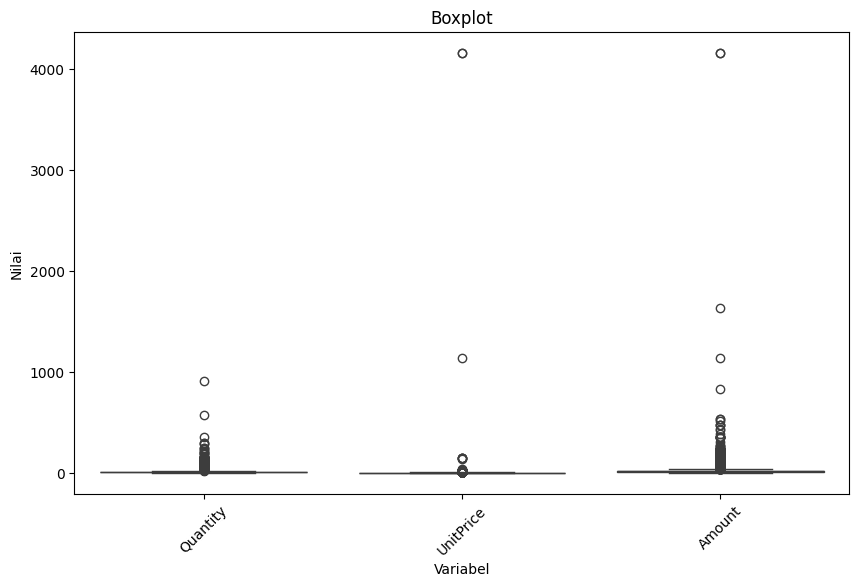

In [61]:
# Ambil kolom bertipe numerik (int dan float)
num_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns

# Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean[num_cols])
plt.title("Boxplot")
plt.xlabel("Variabel")
plt.ylabel("Nilai")
plt.xticks(rotation=45)
plt.show()

In [62]:
# Mengecek konsistensi nama produk untuk setiap StockCode.
df_clean.groupby('StockCode')['ProductName'].nunique().value_counts()

,count
ProductName,
1,1542


Hasilnya menunjukkan bahwa ada 21 StockCode yang masing-masing hanya memiliki 1 ProductName unik. Artinya: setiap StockCode memiliki nama produk yang konsisten (tidak ada variasi atau duplikasi nama).

In [63]:
df_clean.groupby('StockCode')['ProductName'].nunique() \
       .reset_index() \
       .query("ProductName == 1")

,StockCode,ProductName
0,10002,1
1,10120,1
2,10125,1
3,10135,1
4,11001,1
...,...,...
1537,90201B,1
1538,90201C,1
1539,C2,1
1540,M,1


In [64]:
# menghapus outlier
df_clean = df_clean[(np.abs(stats.zscore(df_clean[['Quantity','Amount', 'UnitPrice']])) < 3).all(axis=1)]
df_clean = df_clean.reset_index(drop=True)
df_clean.head()

,InvoiceNo,StockCode,ProductName,Quantity,InvoiceDate,UnitPrice,Country,Amount
0,536370,22728,alarm clock bakelike pink,24,2010-12-01 08:45:00,3.75,France,90.0
1,536370,22727,alarm clock bakelike red,24,2010-12-01 08:45:00,3.75,France,90.0
2,536370,22726,alarm clock bakelike green,12,2010-12-01 08:45:00,3.75,France,45.0
3,536370,21724,panda and bunnies sticker sheet,12,2010-12-01 08:45:00,0.85,France,10.2
4,536370,21883,stars gift tape,24,2010-12-01 08:45:00,0.65,France,15.6


In [65]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8284 entries, 0 to 8283
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    8284 non-null   object        
 1   StockCode    8284 non-null   object        
 2   ProductName  8284 non-null   object        
 3   Quantity     8284 non-null   int64         
 4   InvoiceDate  8284 non-null   datetime64[ns]
 5   UnitPrice    8284 non-null   float64       
 6   Country      8284 non-null   object        
 7   Amount       8284 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 517.9+ KB


# Basket Analysis

In [66]:
# Buat dataframe basket
basket = pd.pivot_table(
    df_clean,
    index='InvoiceNo',
    columns='ProductName',
    values='StockCode',
    aggfunc='nunique',
    fill_value=0
)
basket

ProductName   50's christmas gift bag large   dolly girl beaker  \
InvoiceNo                                                         
536370                                    0                   0   
536852                                    0                   0   
536974                                    0                   0   
537065                                    0                   0   
537463                                    0                   0   
...                                     ...                 ...   
580986                                    0                   0   
581001                                    0                   0   
581171                                    0                   0   
581279                                    0                   0   
581587                                    0                   0   

ProductName   i love london mini backpack   nine drawer office tidy  \
InvoiceNo                                                             
536370                                  0                         0   
536852                                  0                         0   
536974                                  0                         0   
537065                                  0                         0   
537463                                  0                         0   
...                                   ...                       ...   
580986                                  0                         0   
581001                                  0                         0   
581171                                  0                         0   
581279                                  0                         0   
581587                                  0                         0   

ProductName   spaceboy baby gift set   trellis coat rack  \
InvoiceNo                                                  
536370                             0                   0   
536852                             0                   0   
536974                             0                   0   
537065                             0                   0   
537463                             0                   0   
...                              ...                 ...   
580986                             0                   0   
581001                             0                   0   
581171                             0                   0   
581279                             0                   0   
581587                             0                   0   

ProductName  10 colour spaceboy pen  12 coloured party balloons  \
InvoiceNo                                                         
536370                            0                           0   
536852                            0                           0   
536974                            0                           0   
537065                            0                           0   
537463                            0                           0   
...                             ...                         ...   
580986                            0                           0   
581001                            0                           0   
581171                            0                           0   
581279                            0                           0   
581587                            0                           0   

ProductName  12 egg house painted wood  12 message cards with envelopes  \
InvoiceNo                                                                 
536370                               0                                0   
536852                               0                                0   
536974                               0                                0   
537065                               0                                0   
537463                               0                                0   
...                       

In [67]:
basket.info()

<class 'pandas.core.frame.DataFrame'>
Index: 389 entries, 536370 to 581587
Columns: 1538 entries,  50's christmas gift bag large to zinc t-light holder stars small
dtypes: int64(1538)
memory usage: 4.6+ MB


In [68]:
# Encode DataFrame basket dengan nilai True untuk semua nilai di atas 0 dan False untuk semua nilai 0
def encode(x):
    if x == 0:
        return False
    if x > 0:
        return True

basket_encode = basket.applymap(encode)
basket_encode.head()

ProductName   50's christmas gift bag large   dolly girl beaker  \
InvoiceNo                                                         
536370                                False               False   
536852                                False               False   
536974                                False               False   
537065                                False               False   
537463                                False               False   

ProductName   i love london mini backpack   nine drawer office tidy  \
InvoiceNo                                                             
536370                              False                     False   
536852                              False                     False   
536974                              False                     False   
537065                              False                     False   
537463                              False                     False   

ProductName   spaceboy baby gift set   trellis coat rack  \
InvoiceNo                                                  
536370                         False               False   
536852                         False               False   
536974                         False               False   
537065                         False               False   
537463                         False               False   

ProductName  10 colour spaceboy pen  12 coloured party balloons  \
InvoiceNo                                                         
536370                        False                       False   
536852                        False                       False   
536974                        False                       False   
537065                        False                       False   
537463                        False                       False   

ProductName  12 egg house painted wood  12 message cards with envelopes  \
InvoiceNo                                                                 
536370                           False                            False   
536852                           False                            False   
536974                           False                            False   
537065                           False                            False   
537463                           False                            False   

ProductName  12 pencil small tube woodland  \
InvoiceNo                                    
536370                               False   
536852                               False   
536974                               False   
537065                               False   
537463                               False   

ProductName  12 pencils small tube red retrospot  12 pencils small tube skull  \
InvoiceNo                                                                       
536370                                     False                        False   
536852                                     False                        False   
536974                                     False                        False   
537065                                     False                        False   
537463                                     False                        False   

ProductName  12 pencils tall tube posy  12 pencils tall tube red retrospot  \
InvoiceNo                                                                    
536370                           False                               False   
536852                           False                               False   
536974                           False                               False   
537065                           False                               False   
537463                           False                               False   

ProductName  12 pencils tall tube woodland  \
InvoiceNo                                    
536370                               False   
536852                               Fa

In [69]:
# Ambil transaksi dengan banyaknya produk unik lebih dari 1 saja
basket_filter = basket_encode[(basket_encode > 0).sum(axis=1) > 1]
basket_filter.head()

ProductName   50's christmas gift bag large   dolly girl beaker  \
InvoiceNo                                                         
536370                                False               False   
536852                                False               False   
536974                                False               False   
537065                                False               False   
537463                                False               False   

ProductName   i love london mini backpack   nine drawer office tidy  \
InvoiceNo                                                             
536370                              False                     False   
536852                              False                     False   
536974                              False                     False   
537065                              False                     False   
537463                              False                     False   

ProductName   spaceboy baby gift set   trellis coat rack  \
InvoiceNo                                                  
536370                         False               False   
536852                         False               False   
536974                         False               False   
537065                         False               False   
537463                         False               False   

ProductName  10 colour spaceboy pen  12 coloured party balloons  \
InvoiceNo                                                         
536370                        False                       False   
536852                        False                       False   
536974                        False                       False   
537065                        False                       False   
537463                        False                       False   

ProductName  12 egg house painted wood  12 message cards with envelopes  \
InvoiceNo                                                                 
536370                           False                            False   
536852                           False                            False   
536974                           False                            False   
537065                           False                            False   
537463                           False                            False   

ProductName  12 pencil small tube woodland  \
InvoiceNo                                    
536370                               False   
536852                               False   
536974                               False   
537065                               False   
537463                               False   

ProductName  12 pencils small tube red retrospot  12 pencils small tube skull  \
InvoiceNo                                                                       
536370                                     False                        False   
536852                                     False                        False   
536974                                     False                        False   
537065                                     False                        False   
537463                                     False                        False   

ProductName  12 pencils tall tube posy  12 pencils tall tube red retrospot  \
InvoiceNo                                                                    
536370                           False                               False   
536852                           False                               False   
536974                           False                               False   
537065                           False                               False   
537463                           False                               False   

ProductName  12 pencils tall tube woodland  \
InvoiceNo                                    
536370                               False   
536852                               Fa

In [70]:
basket_filter.info()

<class 'pandas.core.frame.DataFrame'>
Index: 372 entries, 536370 to 581587
Columns: 1538 entries,  50's christmas gift bag large to zinc t-light holder stars small
dtypes: bool(1538)
memory usage: 561.6+ KB


# **Apriori Algorithm**
---
Apriori mencari frequent itemsets secara bertahap (level-wise):
1. Hitung support tiap item (1-itemset), buang yang di bawah min_support
2. Gabungkan item yang lolos menjadi kandidat 2-itemset, hitung support, buang yang tidak lolos
3. Ulangi untuk 3-itemset dst. sampai tidak ada kandidat baru

![](https://i.ytimg.com/vi/VBYNmolsa1M/maxresdefault.jpg)

In [71]:
min_support_value = 0.05

frequent_itemsets_apriori = apriori(basket_filter, min_support=min_support_value, use_colnames=True, max_len=3, low_memory=True)

In [72]:
frequent_itemsets_apriori['length'] = frequent_itemsets_apriori['itemsets'].apply(len)

print("10 Itemset Paling Sering (Apriori)\n")
print(frequent_itemsets_apriori.sort_values(by='support', ascending=False).head(10).to_markdown(index=False))

10 Itemset Paling Sering (Apriori)

|   support | itemsets                                                      |   length |
|----------:|:--------------------------------------------------------------|---------:|
|  0.77957  | frozenset({'postage'})                                        |        1 |
|  0.188172 | frozenset({'red toadstool led night light'})                  |        1 |
|  0.174731 | frozenset({'plasters in tin woodland animals'})               |        1 |
|  0.172043 | frozenset({'plasters in tin circus parade '})                 |        1 |
|  0.166667 | frozenset({'rabbit night light'})                             |        1 |
|  0.163978 | frozenset({'round snack boxes set of4 woodland '})            |        1 |
|  0.163978 | frozenset({'red toadstool led night light', 'postage'})       |        2 |
|  0.158602 | frozenset({'lunch bag red retrospot'})                        |        1 |
|  0.153226 | frozenset({'plasters in tin circus parade ', 'postage'})    

In [73]:
product_association = association_rules(frequent_itemsets_apriori, metric="confidence", min_threshold=0.5)

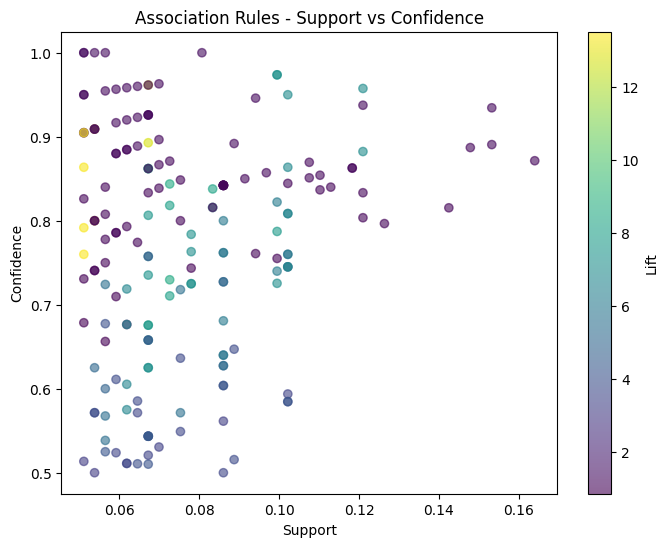

In [74]:
# Plot 2D
plt.figure(figsize=(8,6))
plt.scatter(product_association['support'],
            product_association['confidence'],
            alpha=0.6, c=product_association['lift'], cmap='viridis')

plt.colorbar(label='Lift')
plt.title('Association Rules - Support vs Confidence')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.show()

In [87]:
# Plot 3D
rules_plot = product_association.copy()
rules_plot['antecedents'] = rules_plot['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_plot['consequents'] = rules_plot['consequents'].apply(lambda x: ', '.join(list(x)))

fig = px.scatter_3d(
    rules_plot,
    x='support',
    y='confidence',
    z='lift',
    color='lift',
    size='lift',
    hover_data=['antecedents', 'consequents'],
    title='3D Plot of Association Rules'
)

fig.show()

# **FP-Growth Algorithm**
---
FP-Growth (Frequent Pattern Growth) adalah algoritma yang dirancang untuk menemukan frequent itemsets dengan sangat efisien, terutama pada dataset besar. Perbedaan utamanya dengan Apriori adalah FP-Growth tidak menghasilkan kandidat itemset.

![](https://towardsdatascience.com/wp-content/uploads/2020/10/1P5CAJ1_b89rO09e6hFkWKA.png)


In [75]:
# Transformasi Data (One-Hot Encoding)
basket = (df.groupby(['InvoiceNo', 'ProductName'])['Quantity']
          .sum().unstack().fillna(0))
basket

ProductName   50'S CHRISTMAS GIFT BAG LARGE   DOLLY GIRL BEAKER  \
InvoiceNo                                                         
536370                                  0.0                 0.0   
536852                                  0.0                 0.0   
536974                                  0.0                 0.0   
537065                                  0.0                 0.0   
537463                                  0.0                 0.0   
...                                     ...                 ...   
C579532                                 0.0                 0.0   
C579562                                 0.0                 0.0   
C580161                                 0.0                 0.0   
C580263                                 0.0                 0.0   
C581316                                 0.0                 0.0   

ProductName   I LOVE LONDON MINI BACKPACK   NINE DRAWER OFFICE TIDY  \
InvoiceNo                                                             
536370                                0.0                       0.0   
536852                                0.0                       0.0   
536974                                0.0                       0.0   
537065                                0.0                       0.0   
537463                                0.0                       0.0   
...                                   ...                       ...   
C579532                               0.0                       0.0   
C579562                               0.0                       0.0   
C580161                               0.0                       0.0   
C580263                               0.0                       0.0   
C581316                               0.0                       0.0   

ProductName   SET 2 TEA TOWELS I LOVE LONDON    SPACEBOY BABY GIFT SET  \
InvoiceNo                                                                
536370                                   24.0                      0.0   
536852                                    0.0                      0.0   
536974                                    0.0                      0.0   
537065                                    0.0                      0.0   
537463                                    0.0                      0.0   
...                                       ...                      ...   
C579532                                   0.0                      0.0   
C579562                                   0.0                      0.0   
C580161                                   0.0                      0.0   
C580263                                   0.0                      0.0   
C581316                                   0.0                      0.0   

ProductName   TRELLIS COAT RACK  10 COLOUR SPACEBOY PEN  \
InvoiceNo                                                 
536370                      0.0                     0.0   
536852                      0.0                     0.0   
536974                      0.0                     0.0   
537065                      0.0                     0.0   
537463                      0.0                     0.0   
...                         ...                     ...   
C579532                     0.0                     0.0   
C579562                     0.0                     0.0   
C580161                     0.0                     0.0   
C580263                     0.0                     0.0   
C581316                     0.0                     0.0   

ProductName  12 COLOURED PARTY BALLOONS  12 EGG HOUSE PAINTED WOOD  \
InvoiceNo                                                            
536370                              0.0                        0.0   
536852                              0.0                        0.0   
536974                              0.0                        0.0   
537065                              0.0                        0.0   
537463                              0.0              

In [76]:
def encode_units(x):
    if x <= 0:
        return 0
    if x >= 1:
        return 1

basket_sets = basket.applymap(encode_units)

print("5 Baris Pertama Matriks Transaksi (One-Hot Encoding)")
print(basket_sets.head())

Streaming output truncated to the last 5000 lines.

ProductName  EASTER TIN KEEPSAKE  EDWARDIAN PARASOL BLACK  \
InvoiceNo                                                   
536370                         0                        0   
536852                         0                        0   
536974                         0                        1   
537065                         0                        0   
537463                         0                        0   

ProductName  EDWARDIAN PARASOL NATURAL  EDWARDIAN PARASOL PINK  \
InvoiceNo                                                        
536370                               0                       0   
536852                               0                       0   
536974                               0                       1   
537065                               0                       0   
537463                               0                       0   

ProductName  EDWARDIAN PARASOL RED  EGG CUP MILKMAID HEID

In [77]:
# Algoritma FP-Growth
min_support_value = 0.05

frequent_itemsets = fpgrowth(basket_sets,min_support=min_support_value, use_colnames=True)

In [78]:
# Tampilkan 10 itemset paling sering
print("10 Itemset Paling Sering (Frequent Itemsets)\n")
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
print(frequent_itemsets.sort_values(by='support', ascending=False).head(10).to_markdown(index=False))

10 Itemset Paling Sering (Frequent Itemsets)

|   support | itemsets                                                 |   length |
|----------:|:---------------------------------------------------------|---------:|
|  0.650759 | frozenset({'POSTAGE'})                                   |        1 |
|  0.160521 | frozenset({'RABBIT NIGHT LIGHT'})                        |        1 |
|  0.154013 | frozenset({'RED TOADSTOOL LED NIGHT LIGHT'})             |        1 |
|  0.145336 | frozenset({'PLASTERS IN TIN WOODLAND ANIMALS'})          |        1 |
|  0.143167 | frozenset({'PLASTERS IN TIN CIRCUS PARADE '})            |        1 |
|  0.140998 | frozenset({'POSTAGE', 'RABBIT NIGHT LIGHT'})             |        2 |
|  0.13449  | frozenset({'ROUND SNACK BOXES SET OF4 WOODLAND '})       |        1 |
|  0.13449  | frozenset({'POSTAGE', 'RED TOADSTOOL LED NIGHT LIGHT'})  |        2 |
|  0.130152 | frozenset({'LUNCH BAG RED RETROSPOT'})                   |        1 |
|  0.125813 | frozenset({'POST

In [79]:
# Association Rules
min_confidence_value = 0.5
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_confidence_value)

# Urutkan hasilnya berdasarkan Lift dan Confidence
rules = rules.sort_values(by=['lift', 'confidence'], ascending=False)

# Tampilkan 10 aturan asosiasi teratas
print("\n10 Association Rules Teratas")
print(rules.head(10).to_markdown(index=False))


10 Association Rules Teratas
| antecedents                                                            | consequents                                                            |   antecedent support |   consequent support |   support |   confidence |    lift |   representativity |   leverage |   conviction |   zhangs_metric |   jaccard |   certainty |   kulczynski |
|:-----------------------------------------------------------------------|:-----------------------------------------------------------------------|---------------------:|---------------------:|----------:|-------------:|--------:|-------------------:|-----------:|-------------:|----------------:|----------:|------------:|-------------:|
| frozenset({'CHILDRENS CUTLERY SPACEBOY '})                             | frozenset({'CHILDRENS CUTLERY DOLLY GIRL '})                           |            0.0585683 |            0.0607375 | 0.0542299 |     0.925926 | 15.2447 |                  1 |  0.0506726 |     12.68    |        0.992

# **Insight**
---
Terdapat asosiasi yang sangat kuat antara berbagai varian CHILDRENS CUTLERY serta produk ALARM CLOCK BAKELIKE.

Setiap kali pelanggan membeli CHILDRENS CUTLERY SPACEBOY, terdapat peluang 92% bahwa mereka juga akan membeli CHILDRENS CUTLERY DOLLY GIRL. Peluang kedua produk ini dibeli bersama-sama jauh lebih besar dibanding jika dibeli secara terpisah. Hal yang sama juga terlihat sebaliknya, pelanggan CHILDRENS CUTLERY DOLLY GIRL memiliki peluang 89% untuk turut membeli SPACEBOY.

Pada kelompok alarm, pelanggan yang membeli kombinasi ALARM CLOCK BAKELIKE PINK dan GREEN memiliki peluang 86% untuk juga membeli ALARM CLOCK BAKELIKE RED. Pola ini menunjukkan bahwa ketiga warna jam tersebut cenderung dibeli dalam satu set, dengan peluang dibeli bersama-sama lebih besar daripada dibeli masing-masing.

Hubungan serupa terlihat pada kombinasi warna lain: pelanggan yang membeli ALARM CLOCK BAKELIKE RED memiliki peluang 84% untuk sekaligus membeli ALARM CLOCK BAKELIKE GREEN, dan pelanggan yang membeli GREEN memiliki peluang 83% untuk membeli RED pada transaksi yang sama.

Secara keseluruhan, pola pada tabel menunjukkan bahwa pelanggan cenderung membeli produk-produk CHILDRENS CUTLERY dan ALARM CLOCK BAKELIKE dalam kombinasi warna yang saling melengkapi, bukan secara individual. Oleh karena itu, toko dapat menempatkan produk-produk tersebut berdekatan, menawarkannya sebagai bundle warna, atau memberikan rekomendasi otomatis saat checkout untuk memaksimalkan penjualan set.

# **Fuzzy Association Rule Mining Algorithm**
---
Fuzzy Association Rule Mining adalah teknik penambangan aturan asosiasi yang dikembangkan untuk mengatasi keterbatasan data biner (0 atau 1) dan Diskretisasi Kaku (batas kategori yang tajam)

* Input: Menggunakan derajat keanggotaan (membership degree) (nilai antara 0 hingga 1) sebagai input, bukan hanya 0 atau 1.

* Tujuan: Memungkinkan kita untuk menemukan aturan yang melibatkan atribut kuantitatif dan kualitatif secara bersamaan dan lebih fleksibel. Contohnya: Pelanggan yang membeli Kuantitas Sedang dari Indomie (keanggotaan 0.7) cenderung membeli Gula dengan Harga Murah (keanggotaan 0.9).

* Support Fuzzy: Konsep Support yang digunakan bukan hanya menghitung berapa kali item hadir, tetapi menghitung total dari derajat keanggotaan itemset tersebut di seluruh transaksi.

![](https://media.springernature.com/lw1200/springer-static/image/art%3A10.1007%2Fs40747-021-00607-3/MediaObjects/40747_2021_607_Fig1_HTML.png)

In [80]:
# # Tambahkan kolom TotalPrice
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

In [81]:
# Definisi Fungsi Membership Fuzzy
class FuzzyMembership:
    """
    Kelas untuk menghitung membership degree dari nilai crisp ke fuzzy sets
    """

    @staticmethod
    def trapezoidal(x, a, b, c, d):
        """Membership function trapezoidal"""
        if x <= a or x >= d:
            return 0.0
        elif a < x < b:
            return (x - a) / (b - a)
        elif b <= x <= c:
            return 1.0
        elif c < x < d:
            return (d - x) / (d - c)
        return 0.0

    @staticmethod
    def triangular(x, a, b, c):
        """Membership function triangular"""
        if x <= a or x >= c:
            return 0.0
        elif a < x <= b:
            return (x - a) / (b - a)
        elif b < x < c:
            return (c - x) / (c - b)
        return 0.0

    @staticmethod
    def quantity_fuzzy(quantity):
        """
        Fuzzifikasi untuk Quantity
        - Sedikit: 1-5
        - Sedang: 3-15
        - Banyak: 10-50+
        """
        return {
            'Sedikit': FuzzyMembership.trapezoidal(quantity, 0, 1, 3, 5),
            'Sedang': FuzzyMembership.triangular(quantity, 3, 8, 15),
            'Banyak': FuzzyMembership.trapezoidal(quantity, 10, 20, 50, 100)
        }

    @staticmethod
    def price_fuzzy(price):
        """
        Fuzzifikasi untuk Unit Price
        - Murah: 0-50000
        - Sedang: 30000-150000
        - Mahal: 100000-500000+
        """
        return {
            'Murah': FuzzyMembership.trapezoidal(price, 0, 5000, 30000, 50000),
            'Sedang': FuzzyMembership.triangular(price, 30000, 80000, 150000),
            'Mahal': FuzzyMembership.trapezoidal(price, 100000, 200000, 500000, 1000000)
        }

    @staticmethod
    def total_price_fuzzy(total):
        """
        Fuzzifikasi untuk Total Price
        - Rendah: 0-100000
        - Sedang: 50000-300000
        - Tinggi: 200000-1000000+
        """
        return {
            'Rendah': FuzzyMembership.trapezoidal(total, 0, 10000, 50000, 100000),
            'Sedang': FuzzyMembership.triangular(total, 50000, 150000, 300000),
            'Tinggi': FuzzyMembership.trapezoidal(total, 200000, 400000, 1000000, 2000000)
        }

![](https://www.nidec.com/files/user/www-nidec-com/technology/motor/glossary/item/trapezoidal_wave-01.jpg)

In [82]:
# Transformasi Data ke Fuzzy Transactions
def create_fuzzy_transactions(df):
    """
    Mengubah data crisp menjadi fuzzy transactions
    Setiap item akan menjadi: ProductName_FuzzyAttribute
    """
    fuzzy_transactions = []

    for invoice, group in df.groupby('InvoiceNo'):
        fuzzy_items = {}

        for idx, row in group.iterrows():
            product = row['ProductName']
            quantity = row['Quantity']
            unit_price = row['UnitPrice']
            total_price = row['TotalPrice']

            # Fuzzifikasi Quantity
            qty_fuzzy = FuzzyMembership.quantity_fuzzy(quantity)
            for fuzzy_label, membership in qty_fuzzy.items():
                if membership > 0:
                    item_name = f"{product}_Qty_{fuzzy_label}"
                    fuzzy_items[item_name] = max(fuzzy_items.get(item_name, 0), membership)

            # Fuzzifikasi Unit Price
            price_fuzzy = FuzzyMembership.price_fuzzy(unit_price)
            for fuzzy_label, membership in price_fuzzy.items():
                if membership > 0:
                    item_name = f"{product}_Price_{fuzzy_label}"
                    fuzzy_items[item_name] = max(fuzzy_items.get(item_name, 0), membership)

            # Fuzzifikasi Total Price
            total_fuzzy = FuzzyMembership.total_price_fuzzy(total_price)
            for fuzzy_label, membership in total_fuzzy.items():
                if membership > 0:
                    item_name = f"{product}_Total_{fuzzy_label}"
                    fuzzy_items[item_name] = max(fuzzy_items.get(item_name, 0), membership)

        fuzzy_transactions.append(fuzzy_items)

    return fuzzy_transactions

fuzzy_transactions = create_fuzzy_transactions(df)
print(f"Total fuzzy transactions: {len(fuzzy_transactions)}")
print(f"\nContoh fuzzy transaction pertama:")
for item, membership in list(fuzzy_transactions[0].items())[:5]:
    print(f"  {item}: {membership:.3f}")

Total fuzzy transactions: 461

Contoh fuzzy transaction pertama:
  ALARM CLOCK BAKELIKE PINK_Qty_Banyak: 1.000
  ALARM CLOCK BAKELIKE PINK_Price_Murah: 0.001
  ALARM CLOCK BAKELIKE PINK_Total_Rendah: 0.009
  ALARM CLOCK BAKELIKE RED _Qty_Banyak: 1.000
  ALARM CLOCK BAKELIKE RED _Price_Murah: 0.001


In [83]:
# Fuzzy Apriori Algorithm

class FuzzyApriori:
    def __init__(self, min_support=0.05):
        self.min_support = min_support
        self.frequent_itemsets = []

    def calculate_fuzzy_support(self, itemset, transactions):
        """
        Hitung fuzzy support menggunakan minimum operator (T-norm)
        """
        total_support = 0
        for transaction in transactions:

            # Hitung membership untuk itemset (gunakan minimum)
            memberships = []
            for item in itemset:
                memberships.append(transaction.get(item, 0))

            if memberships:
                total_support += min(memberships)

        return total_support / len(transactions)

    def fit(self, transactions):
        """
        Jalankan Fuzzy Apriori
        """

        # Generate 1-itemsets
        all_items = set()
        for transaction in transactions:
            all_items.update(transaction.keys())

        # Hitung support untuk 1-itemsets
        frequent_1 = {}
        for item in all_items:
            support = self.calculate_fuzzy_support([item], transactions)
            if support >= self.min_support:
                frequent_1[frozenset([item])] = support
                self.frequent_itemsets.append({
                    'itemsets': frozenset([item]),
                    'support': support,
                    'length': 1
                })

        print(f"Frequent 1-itemsets: {len(frequent_1)}")

        # Generate k-itemsets (k >= 2)
        k = 2
        current_frequent = frequent_1

        while current_frequent and k <= 3:
            print(f"Generating {k}-itemsets...")
            candidates = self._generate_candidates(list(current_frequent.keys()), k)
            print(f"  Candidates: {len(candidates)}")

            next_frequent = {}
            for candidate in candidates:
                support = self.calculate_fuzzy_support(candidate, transactions)
                if support >= self.min_support:
                    next_frequent[candidate] = support
                    self.frequent_itemsets.append({
                        'itemsets': candidate,
                        'support': support,
                        'length': k
                    })

            print(f"  Frequent {k}-itemsets: {len(next_frequent)}")
            current_frequent = next_frequent
            k += 1

        return pd.DataFrame(self.frequent_itemsets)

    def _generate_candidates(self, frequent_itemsets, k):
        """
        Generate kandidat k-itemsets dari (k-1)-itemsets
        """
        candidates = []
        n = len(frequent_itemsets)

        for i in range(n):
            for j in range(i + 1, n):
                union = frequent_itemsets[i] | frequent_itemsets[j]
                if len(union) == k and union not in candidates:
                    candidates.append(union)

        return candidates

# Jalankan Fuzzy Apriori
min_support_value = 0.03
print(f"Menjalankan Fuzzy Apriori dengan min_support = {min_support_value}\n")

fuzzy_apriori = FuzzyApriori(min_support=min_support_value)
frequent_itemsets_fuzzy = fuzzy_apriori.fit(fuzzy_transactions)

Menjalankan Fuzzy Apriori dengan min_support = 0.03

Frequent 1-itemsets: 64
Generating 2-itemsets...
  Candidates: 2016
  Frequent 2-itemsets: 27
Generating 3-itemsets...
  Candidates: 278
  Frequent 3-itemsets: 0


In [84]:
# Hasil
print(f"{'='*60}")
print("HASIL FUZZY ASSOCIATION RULE MINING")
print(f"{'='*60}")
print(f"Total fuzzy frequent itemsets: {len(frequent_itemsets_fuzzy)}")

frequent_itemsets_fuzzy = frequent_itemsets_fuzzy.sort_values(by=['support', 'length'], ascending=[False, False])

print("Top 15 Frequent Fuzzy Itemsets\n")
display_df = frequent_itemsets_fuzzy.head(15).copy()
display_df['itemsets_str'] = display_df['itemsets'].apply(lambda x: ', '.join(list(x)[:3]))
print(display_df[['itemsets_str', 'support', 'length']].to_markdown(index=False))

HASIL FUZZY ASSOCIATION RULE MINING
Total fuzzy frequent itemsets: 91
Top 15 Frequent Fuzzy Itemsets

| itemsets_str                                       |   support |   length |
|:---------------------------------------------------|----------:|---------:|
| POSTAGE_Qty_Sedikit                                | 0.52603   |        1 |
| RABBIT NIGHT LIGHT_Qty_Banyak                      | 0.0885033 |        1 |
| PACK OF 72 RETROSPOT CAKE CASES_Qty_Banyak         | 0.0824295 |        1 |
| REGENCY CAKESTAND 3 TIER_Qty_Sedikit               | 0.0748373 |        1 |
| RED RETROSPOT MINI CASES_Qty_Sedikit               | 0.0704989 |        1 |
| RED TOADSTOOL LED NIGHT LIGHT_Qty_Banyak           | 0.0703688 |        1 |
| MINI PAINT SET VINTAGE _Qty_Banyak                 | 0.0692408 |        1 |
| RABBIT NIGHT LIGHT_Qty_Banyak, POSTAGE_Qty_Sedikit | 0.0680694 |        2 |
| POSTAGE_Qty_Sedang                                 | 0.0662535 |        1 |
| SET/10 RED POLKADOT PARTY CANDLES_Qty_

In [85]:
# Fuzzy Association Rules
def generate_fuzzy_rules(frequent_itemsets_df, transactions, min_confidence=0.4):

    rules = []
    support_dict = {}

    for idx, row in frequent_itemsets_df.iterrows():
        support_dict[row['itemsets']] = row['support']

    fuzzy_apriori_temp = FuzzyApriori(min_support=0)

    for idx, row in frequent_itemsets_df[frequent_itemsets_df['length'] >= 2].iterrows():
        itemset = row['itemsets']
        itemset_support = row['support']
        items = list(itemset)

        for i in range(1, len(items)):
            for antecedent_items in combinations(items, i):
                antecedent = frozenset(antecedent_items)
                consequent = itemset - antecedent

                if antecedent in support_dict:
                    antecedent_support = support_dict[antecedent]
                    confidence = itemset_support / antecedent_support if antecedent_support > 0 else 0

                    if confidence >= min_confidence:
                        if consequent in support_dict:
                            consequent_support = support_dict[consequent]
                            lift = confidence / consequent_support if consequent_support > 0 else 0
                        else:
                            consequent_support = fuzzy_apriori_temp.calculate_fuzzy_support(
                                consequent, transactions
                            )
                            lift = confidence / consequent_support if consequent_support > 0 else 0

                        rules.append({
                            'antecedents': antecedent,
                            'consequents': consequent,
                            'support': itemset_support,
                            'confidence': confidence,
                            'lift': lift
                        })

    return pd.DataFrame(rules)

print("Fuzzy Association Rules")
min_confidence_value = 0.4
rules_fuzzy = generate_fuzzy_rules(
    frequent_itemsets_fuzzy,
    fuzzy_transactions,
    min_confidence=min_confidence_value
)

if len(rules_fuzzy) > 0:
    rules_fuzzy = rules_fuzzy.sort_values(by=['lift', 'confidence'], ascending=False)
    print(f"Total fuzzy rules: {len(rules_fuzzy)}")

    print("\nTop 10 Fuzzy Association Rules")
    display_rules = rules_fuzzy.head(10).copy()
    display_rules['rule'] = display_rules.apply(
        lambda x: f"{list(x['antecedents'])[0][:30]} => {list(x['consequents'])[0][:30]}",
        axis=1
    )
    print(display_rules[['rule', 'support', 'confidence', 'lift']].to_markdown(index=False))

    print("\nStatistik Fuzzy Rules")
    print(f"Average confidence: {rules_fuzzy['confidence'].mean():.4f}")
    print(f"Average lift: {rules_fuzzy['lift'].mean():.4f}")
    print(f"Max lift: {rules_fuzzy['lift'].max():.4f}")
else:
    print("Tidak ada rules yang memenuhi kriteria")
    print("Coba turunkan min_support atau min_confidence")

Fuzzy Association Rules
Total fuzzy rules: 30

Top 10 Fuzzy Association Rules
| rule                                                             |   support |   confidence |     lift |
|:-----------------------------------------------------------------|----------:|-------------:|---------:|
| DOLLY GIRL CHILDRENS BOWL_Qty_ => SPACEBOY CHILDRENS BOWL_Qty_Se | 0.0308026 |     0.876543 | 22.2026  |
| SPACEBOY CHILDRENS BOWL_Qty_Se => DOLLY GIRL CHILDRENS BOWL_Qty_ | 0.0308026 |     0.78022  | 22.2026  |
| SET/6 RED SPOTTY PAPER PLATES_ => SET/6 RED SPOTTY PAPER CUPS_Qt | 0.0403471 |     0.895954 | 16.79    |
| SET/6 RED SPOTTY PAPER CUPS_Qt => SET/6 RED SPOTTY PAPER PLATES_ | 0.0403471 |     0.756098 | 16.79    |
| SET/6 RED SPOTTY PAPER CUPS_Qt => SET/20 RED RETROSPOT PAPER NAP | 0.0303688 |     0.569106 | 13.3312  |
| SET/20 RED RETROSPOT PAPER NAP => SET/6 RED SPOTTY PAPER CUPS_Qt | 0.0303688 |     0.711382 | 13.3312  |
| JUMBO BAG WOODLAND ANIMALS_Qty => POSTAGE_Qty_Sedikit           

# **Insight**
---

Kami menemukan pola pembelian yang sangat kuat antara DOLLY GIRL CHILDRENS BOWL dan SPACEBOY CHILDRENS BOWL.
Ketika pelanggan membeli DOLLY GIRL CHILDRENS BOWL dalam jumlah tertentu, terdapat peluang ≈88% bahwa mereka juga akan membeli SPACEBOY CHILDRENS BOWL.
Pola ini 22 kali lebih besar dibanding jika pembelian keduanya terjadi secara acak, menunjukkan bahwa kedua produk ini hampir selalu dibeli bersamaan.

Arah sebaliknya juga kuat: ketika pelanggan membeli SPACEBOY CHILDRENS BOWL, terdapat peluang ≈78% bahwa mereka juga membeli DOLLY GIRL CHILDRENS BOWL pada transaksi yang sama.
Hal ini menandakan bahwa kedua mangkuk anak ini cenderung dianggap satu set oleh pelanggan.

Temuan kuat lainnya muncul pada produk pesta:
ketika pelanggan membeli SET/6 RED SPOTTY PAPER PLATES, terdapat peluang ≈90% bahwa mereka juga akan membeli SET/6 RED SPOTTY PAPER CUPS.
Pola pembelian keduanya jauh lebih tinggi daripada kebetulan, menunjukkan bahwa pelanggan menginginkan paket perlengkapan pesta yang serasi.